# 05 — Final results and the prediction file

The test split was held out of every decision in notebooks 02–04 and scored once, by
`run_final.py`. This notebook reads what that run wrote.

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')
EXP = '../experiments/'

results = pd.read_csv(EXP + 'final_test_results.csv')
gap = pd.read_csv(EXP + 'generalisation_gap.csv')
cfg = json.load(open('../models/config.json'))
preds = pd.read_csv('../outputs/final_predictions.csv')
probs = pd.read_csv('../outputs/final_prediction_probabilities.csv')

## The model that was shipped

In [2]:
print(json.dumps(cfg, indent=2))

{
  "model": "HistGradientBoostingClassifier (sklearn), tuned, uncalibrated",
  "artifact": "final_model.joblib",
  "params": {
    "l2_regularization": 0.02715581955282941,
    "learning_rate": 0.014830392684568025,
    "max_iter": 234,
    "max_leaf_nodes": 16,
    "min_samples_leaf": 81
  },
  "drop_sex": true,
  "threshold": 0.3175675758037982,
  "threshold_rule": "flag the riskiest 20% of the scored population",
  "capacity": 0.2,
  "trained_on": "UCI default of credit card clients, train split"
}


## Test results, against the baseline that matters

The majority-class row is there so the accuracy column cannot be read on its own. It scores
78% accuracy and catches zero defaulters, which is the trap this problem is built around.

In [3]:
display(results.round(4))

model_row = results[results.model.str.contains('capacity')].iloc[0]
base_row = results.iloc[0]
print(f"ROC-AUC {model_row.roc_auc:.4f}")
print(f"PR-AUC  {model_row.pr_auc:.4f} against a no-skill floor of {model_row.pr_auc_no_skill:.4f} "
      f"({model_row.pr_auc / model_row.pr_auc_no_skill:.1f}x)")
print(f"accuracy {model_row.accuracy:.4f} vs {base_row.accuracy:.4f} for the majority class "
      f"-- a {model_row.accuracy - base_row.accuracy:+.4f} difference, which is why accuracy is not the metric")
print(f"at the {cfg['capacity']:.0%} cutoff: {model_row.precision:.1%} of flagged accounts default, "
      f"{model_row.lift:.2f}x better than flagging the same number at random, "
      f"catching {model_row.recall:.1%} of all defaulters")

,model,roc_auc,pr_auc,pr_auc_no_skill,brier,accuracy,precision,recall,specificity,f1,flagged_rate,lift,threshold
0,majority class (predict 'no default'),0.5000,0.2211,0.2211,NaN,0.7789,NaN,0.0000,NaN,0.0000,NaN,NaN,NaN
1,HGB (no SEX) @ 20% capacity cutoff,0.7815,0.5612,0.2211,0.1339,0.8063,0.5695,0.5076,0.8911,0.5367,0.1970,2.5760,0.3176
2,HGB (no SEX) @ 0.5 for reference,0.7815,0.5612,0.2211,0.1339,0.8217,0.6928,0.3474,0.9563,0.4628,0.1109,3.1337,0.5000


ROC-AUC 0.7815
PR-AUC  0.5612 against a no-skill floor of 0.2211 (2.5x)
accuracy 0.8063 vs 0.7789 for the majority class -- a +0.0274 difference, which is why accuracy is not the metric
at the 20% cutoff: 56.9% of flagged accounts default, 2.58x better than flagging the same number at random, catching 50.8% of all defaulters


## Did it generalise?

Validation was used for model choice, hyperparameters and the cutoff, so it is optimistic by
construction. The gap to test is the size of that optimism.

In [4]:
display(gap.round(4))
d = gap[gap.split == 'delta'].iloc[0]
print(f"ROC-AUC fell {abs(d.roc_auc):.4f} and PR-AUC {abs(d.pr_auc):.4f} from validation to test")
print('small enough to be ordinary selection optimism rather than overfitting')

,split,roc_auc,pr_auc,brier,precision,recall,f1
0,validation,0.7965,0.5795,0.1310,0.5776,0.5223,0.5486
1,test,0.7815,0.5612,0.1339,0.5695,0.5076,0.5367
2,delta,-0.0150,-0.0183,0.0029,-0.0081,-0.0147,-0.0118


ROC-AUC fell 0.0150 and PR-AUC 0.0183 from validation to test
small enough to be ordinary selection optimism rather than overfitting


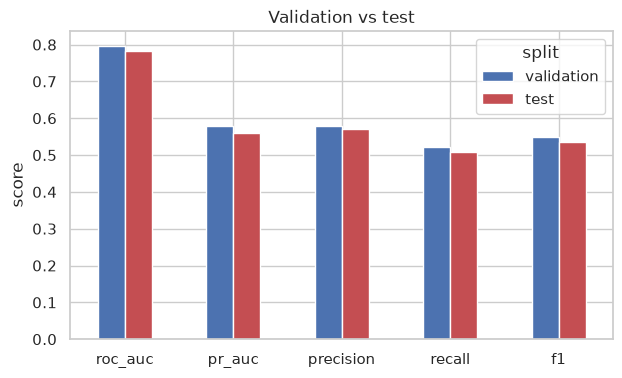

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
plot = gap[gap.split != 'delta'].set_index('split')[['roc_auc', 'pr_auc', 'precision', 'recall', 'f1']]
plot.T.plot.bar(ax=ax, rot=0, color=['#4c72b0', '#c44e52'])
ax.set_ylabel('score'); ax.set_title('Validation vs test')
plt.show()

## The deliverable

`outputs/final_predictions.csv` — one row per customer in the Finance Club's unlabelled
validation file, with the flag from the capacity cutoff.

These customers come from the same source as the training data, so this file is the required
deliverable, **not an evaluation**. The honest estimate of performance is the test table above.

In [6]:
print(f"{len(preds):,} rows")
display(preds.head())
print(f"flagged: {preds.next_month_default.sum():,} ({preds.next_month_default.mean():.2%}) "
      f"at threshold {cfg['threshold']:.4f}")
print(f"columns: {list(preds.columns)}")

5,016 rows


,Customer,next_month_default
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


flagged: 916 (18.26%) at threshold 0.3176
columns: ['Customer', 'next_month_default']


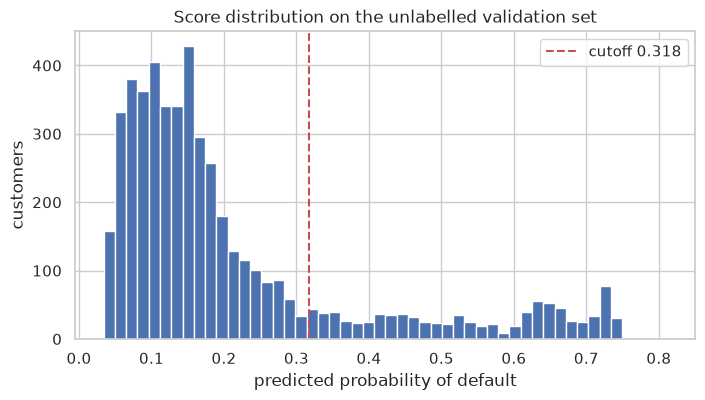

,default_probability
count,5016.0000
mean,0.2123
std,0.1770
min,0.0339
25%,0.0969
50%,0.1494
75%,0.2426
max,0.8115


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(probs.default_probability, bins=50, color='#4c72b0')
ax.axvline(cfg['threshold'], color='#c44e52', ls='--',
           label=f"cutoff {cfg['threshold']:.3f}")
ax.set_xlabel('predicted probability of default'); ax.set_ylabel('customers')
ax.set_title('Score distribution on the unlabelled validation set'); ax.legend()
plt.show()
display(probs.default_probability.describe().round(4).to_frame())

## Limitations

- **One month ahead.** The target is October 2005 only. Nothing here says anything about a
  customer's behaviour a year out.
- **2005 Taiwan.** A different market and a different era of credit. The method transfers;
  these coefficients do not.
- **No out-of-time test.** Every customer is observed over the same six months, so the split
  measures generalisation to unseen *customers*, not to a future *period*. A real scorecard
  would be validated on a later cohort.
- **The 20% is assumed.** Review capacity was never given. It is a stated assumption, and the
  threshold sweep in notebook 04 shows what any other value would cost.